# SVD and Image Compression

**Source:** https://labs.acme.byu.edu/Volume1/SVD_ImageCompression/SVD_ImageCompression.html

Every $m\times n$ matrix $A$ of rank $r$ factors as $A = U\Sigma V^H$, where $U$ and $V$ have orthonormal columns and $\Sigma$ is diagonal with the singular values $\sigma_1\ge\sigma_2\ge\dots\ge0$. The SVD reads a matrix as rotate, stretch, rotate. Truncating it after $s$ terms gives the best rank-$s$ approximation in both the 2-norm and the Frobenius norm (Schmidt, Mirsky, Eckart-Young). This lab builds the compact SVD from an eigensolver, visualizes it, and uses truncation to compress images.

In [1]:
import os, io, zipfile, urllib.request
import numpy as np
import matplotlib.pyplot as plt
from imageio.v3 import imread
from scipy import linalg as la

DATA = "data"
DATA_ZIP = "https://labs.acme.byu.edu/_downloads/f0adb14f448aea2a3488f45e40d3f7de/SVD_ImageCompression.zip"
needed = ["hubble.jpg", "hubble_gray.jpg"]
os.makedirs(DATA, exist_ok=True)
if not all(os.path.exists(os.path.join(DATA, f)) for f in needed):
    with zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(DATA_ZIP).read())) as z:
        for f in needed:
            with open(os.path.join(DATA, f), "wb") as fh:
                fh.write(z.read(f))

rng = np.random.default_rng(0)

## Full and Compact SVD

- **Full SVD** $A = U\Sigma V^H$: $U$ is $m\times m$, $\Sigma$ is $m\times n$, $V$ is $n\times n$.
- **Compact SVD** $A = U_1\Sigma_1V_1^H$: keep only the $r$ nonzero singular values and the matching columns of $U$ and $V$.

The compact SVD gives the outer-product expansion $A = \sum_{i=1}^r \sigma_i \mathbf{u}_i\mathbf{v}_i^H$.

**Algorithm 1 (Compact SVD).** Take the eigendecomposition of $A^HA$. The singular values are the square roots of its eigenvalues, and $V$ holds its eigenvectors. Sort both in decreasing order, keep the $r$ singular values above a tolerance, then set $U_1 = AV_1/\boldsymbol\sigma_1$ (column-wise, using $A\mathbf{v}_i = \sigma_i\mathbf{u}_i$).

---

## Problem 1: Compact SVD via Algorithm 1

In [2]:
def compact_svd(A, tol=1e-6):
    """Compute the truncated SVD of A.

    Parameters:
        A ((m,n) ndarray): The matrix (of rank r) to factor.
        tol (float): The tolerance for excluding singular values.

    Returns:
        ((m,r) ndarray): The orthonormal matrix U in the SVD.
        ((r,) ndarray): The singular values of A as a 1-D array.
        ((r,n) ndarray): The orthonormal matrix V^H in the SVD.
    """
    lam, V = la.eigh(A.conj().T @ A)          # A^H A is Hermitian
    sigma = np.sqrt(np.clip(lam, 0, None))    # clip tiny negative roundoff
    order = np.argsort(sigma)[::-1]
    sigma, V = sigma[order], V[:, order]
    r = int(np.sum(sigma > tol))
    sigma1, V1 = sigma[:r], V[:, :r]
    U1 = A @ V1 / sigma1                       # broadcasting divides each column
    return U1, sigma1, V1.conj().T

`la.eigh()` is used instead of `la.eig()` because $A^HA$ is Hermitian. It returns real eigenvalues and an orthonormal eigenbasis even when eigenvalues repeat.

Check the function on full-rank, rank-deficient, and complex matrices: $U$ and $V$ should be orthonormal, $U\Sigma V^H$ should reproduce $A$, the number of singular values should equal the rank, and the singular values should agree with SciPy.

In [3]:
def check_svd(A, label):
    U, s, Vh = compact_svd(A)
    r = len(s)
    print(f"{label}: shape {A.shape}, rank {np.linalg.matrix_rank(A)}, r = {r}")
    print("  U^H U = I        :", np.allclose(U.conj().T @ U, np.eye(r)))
    print("  V^H V = I        :", np.allclose(Vh @ Vh.conj().T, np.eye(r)))
    print("  U diag(s) V^H = A:", np.allclose(U @ np.diag(s) @ Vh, A))
    print("  sigma matches la.svd:", np.allclose(s, la.svd(A, compute_uv=False)[:r]))

check_svd(rng.random((10, 5)), "random 10x5")
check_svd(rng.random((6, 4)) @ rng.random((4, 9)), "rank-4 6x9")
check_svd(rng.random((7, 7)) + 1j * rng.random((7, 7)), "complex 7x7")

random 10x5: shape (10, 5), rank 5, r = 5
  U^H U = I        : True
  V^H V = I        : True
  U diag(s) V^H = A: True
  sigma matches la.svd: True
rank-4 6x9: shape (6, 9), rank 4, r = 4
  U^H U = I        : True
  V^H V = I        : True
  U diag(s) V^H = A: True
  sigma matches la.svd: True
complex 7x7: shape (7, 7), rank 7, r = 7
  U^H U = I        : True
  V^H V = I        : True
  U diag(s) V^H = A: True
  sigma matches la.svd: True


---

## Problem 2: Visualizing the SVD

For a $2\times2$ matrix $A$, $V^H$ rotates (or reflects) the plane, $\Sigma$ stretches along the coordinate axes, and $U$ rotates again. Track the unit circle $S$ and the standard basis vectors $E = [\mathbf{e}_1\,|\,\mathbf{0}\,|\,\mathbf{e}_2]$ through each step.

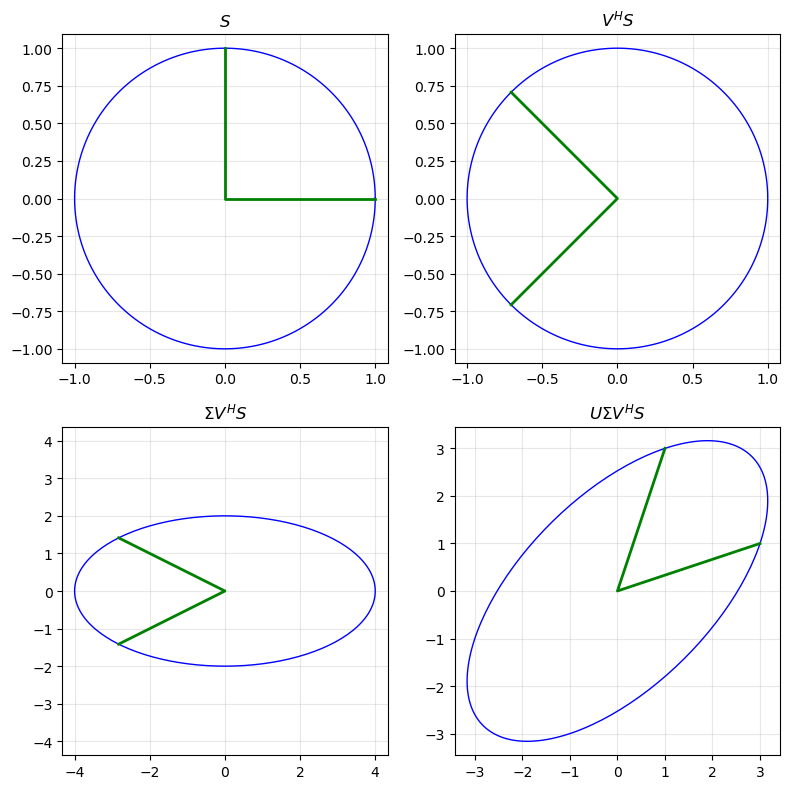

In [4]:
def visualize_svd(A):
    """Plot the effect of the SVD of A as a sequence of linear transformations
    on the unit circle and the two standard basis vectors.
    """
    theta = np.linspace(0, 2 * np.pi, 200)
    S = np.vstack((np.cos(theta), np.sin(theta)))
    E = np.array([[1, 0, 0], [0, 0, 1]])
    U, s, Vh = la.svd(A)
    Sigma = np.diag(s)

    steps = [(np.eye(2), r"$S$"),
             (Vh, r"$V^H S$"),
             (Sigma @ Vh, r"$\Sigma V^H S$"),
             (U @ Sigma @ Vh, r"$U\Sigma V^H S$")]
    fig, axes = plt.subplots(2, 2, figsize=(8, 8))
    for ax, (M, title) in zip(axes.ravel(), steps):
        MS, ME = M @ S, M @ E
        ax.plot(MS[0], MS[1], "b-", lw=1)
        ax.plot(ME[0], ME[1], "g-", lw=2)
        ax.set_title(title)
        ax.axis("equal")
        ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

visualize_svd(np.array([[3, 1], [1, 3]]))

For $A = \begin{bmatrix}3&1\\1&3\end{bmatrix}$, the singular values are $4$ and $2$, so the circle becomes an ellipse with semi-axes $4$ and $2$ along the diagonals. This matches Fig. 1 of the lab.

## Low-Rank Approximations

Storing the compact SVD takes $mr + r + nr$ numbers instead of $mn$. The **truncated SVD** keeps only the first $s<r$ terms,

$$A_s = \sum_{i=1}^s \sigma_i\mathbf{u}_i\mathbf{v}_i^H,$$

which is the best rank-$s$ approximation of $A$ in both the 2-norm and the Frobenius norm.

---

## Problem 3: Best Rank-$s$ Approximation

In [5]:
def svd_approx(A, s):
    """Return the best rank s approximation to A with respect to the 2-norm
    and the Frobenius norm, along with the number of bytes needed to store
    the approximation via the truncated SVD.

    Parameters:
        A ((m,n), ndarray)
        s (int): The rank of the desired approximation.

    Returns:
        ((m,n), ndarray) The best rank s approximation of A.
        (int) The number of entries needed to store the truncated SVD.
    """
    U, sigma, Vh = la.svd(A, full_matrices=False)
    if s > np.sum(sigma > 1e-12 * sigma[0]):
        raise ValueError(f"s = {s} exceeds rank(A)")
    Uh, sh, Vhh = U[:, :s], sigma[:s], Vh[:s]
    return (Uh * sh) @ Vhh, Uh.size + sh.size + Vhh.size


A = rng.random((20, 30))
for s in [1, 5, 10, 20]:
    As, entries = svd_approx(A, s)
    print(f"s = {s:2d}: rank(A_s) = {np.linalg.matrix_rank(As):2d}, "
          f"entries = {entries:4d} (vs {A.size}), ||A - A_s||_F = {la.norm(A - As):.4f}")
try:
    svd_approx(A, 21)
except ValueError as e:
    print("ValueError:", e)

s =  1: rank(A_s) =  1, entries =   51 (vs 600), ||A - A_s||_F = 6.6014
s =  5: rank(A_s) =  5, entries =  255 (vs 600), ||A - A_s||_F = 4.7923
s = 10: rank(A_s) = 10, entries =  510 (vs 600), ||A - A_s||_F = 2.9474
s = 20: rank(A_s) = 20, entries = 1020 (vs 600), ||A - A_s||_F = 0.0000
ValueError: s = 21 exceeds rank(A)


### Unit tests for Problem 3

The lab asks for a `test_svd_approx` unit test. It is written pytest-style here and run in place.

In [6]:
def test_svd_approx():
    rng = np.random.default_rng(1)
    A = rng.random((15, 10))
    m, n = A.shape
    sigma = la.svd(A, compute_uv=False)
    for s in range(1, 11):
        As, entries = svd_approx(A, s)
        assert As.shape == A.shape
        assert np.linalg.matrix_rank(As) == s
        assert entries == s * (m + n + 1)
        # Eckart-Young: the 2-norm error is the next singular value
        if s < 10:
            assert np.isclose(la.norm(A - As, 2), sigma[s])
    # Full rank reproduces A
    assert np.allclose(svd_approx(A, 10)[0], A)
    # Rank-deficient input: s > rank raises
    B = rng.random((8, 3)) @ rng.random((3, 8))
    assert np.allclose(svd_approx(B, 3)[0], B)
    try:
        svd_approx(B, 4)
        assert False, "expected ValueError"
    except ValueError:
        pass

test_svd_approx()
print("PASS test_svd_approx")

PASS test_svd_approx


## Error of Low-Rank Approximations

The Eckart-Young theorem also gives the exact 2-norm error: $\|A - A_s\|_2 = \sigma_{s+1}$. To approximate $A$ within a tolerance $\varepsilon$, choose the smallest $s$ with $\sigma_{s+1} < \varepsilon$.

---

## Problem 4: Lowest-Rank Approximation Within $\varepsilon$

In [7]:
def lowest_rank_approx(A, err):
    """Return the lowest rank approximation of A with error less than 'err'
    with respect to the matrix 2-norm, along with the number of bytes needed
    to store the approximation via the truncated SVD.

    Parameters:
        A ((m, n) ndarray)
        err (float): Desired maximum error.

    Returns:
        A_s ((m,n) ndarray) The lowest rank approximation of A satisfying
            ||A - A_s||_2 < err.
        (int) The number of entries needed to store the truncated SVD.
    """
    U, sigma, Vh = la.svd(A, full_matrices=False)
    if err <= sigma[-1]:
        raise ValueError("A cannot be approximated within the tolerance by a matrix of lesser rank")
    # sigma[s] is sigma_{s+1}; take the first index where it drops below err.
    s = int(np.argmax(sigma < err))
    Uh, sh, Vhh = U[:, :s], sigma[:s], Vh[:s]
    return (Uh * sh) @ Vhh, Uh.size + sh.size + Vhh.size


A = rng.random((40, 25))
sigma = la.svd(A, compute_uv=False)
print("singular values:", np.round(sigma[:8], 3), "...")
# Tolerances between consecutive singular values, so each one picks out a known rank.
for eps in [(sigma[0] + sigma[1]) / 2, (sigma[3] + sigma[4]) / 2,
            (sigma[11] + sigma[12]) / 2, (sigma[-2] + sigma[-1]) / 2]:
    As, entries = lowest_rank_approx(A, eps)
    err2 = la.norm(A - As, 2)
    print(f"eps = {eps:6.3f}: rank {np.linalg.matrix_rank(As):2d}, ||A - A_s||_2 = {err2:.4f} < eps: {err2 < eps}, entries = {entries}")
try:
    lowest_rank_approx(A, sigma[-1] / 2)
except ValueError as e:
    print("ValueError:", e)

singular values: [15.867  2.88   2.755  2.682  2.574  2.557  2.461  2.225] ...
eps =  9.374: rank  1, ||A - A_s||_2 = 2.8801 < eps: True, entries = 66
eps =  2.628: rank  4, ||A - A_s||_2 = 2.5739 < eps: True, entries = 264
eps =  1.696: rank 12, ||A - A_s||_2 = 1.6576 < eps: True, entries = 792
eps =  0.455: rank 24, ||A - A_s||_2 = 0.3868 < eps: True, entries = 1584
ValueError: A cannot be approximated within the tolerance by a matrix of lesser rank


## Image Compression

A photograph's singular values start large and fall off quickly, so most of the image lives in a few singular triples. Here are the singular values of the Hubble image (Fig. 2 in the lab).

gray: (1158, 1041)  color: (1158, 1041, 3)


rank = 1041, singular values < sigma_1/100: 913


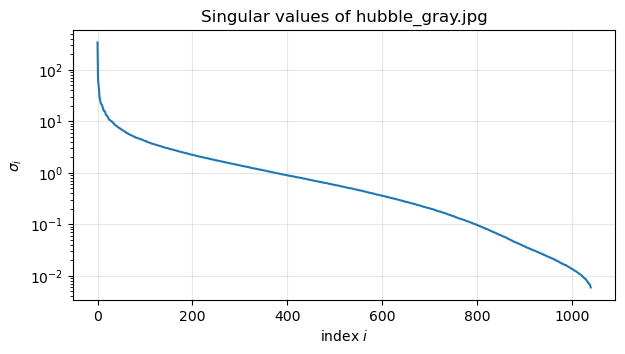

In [8]:
hubble_gray = imread(os.path.join(DATA, "hubble_gray.jpg")) / 255.
hubble = imread(os.path.join(DATA, "hubble.jpg")) / 255.
print("gray:", hubble_gray.shape, " color:", hubble.shape)

sv = la.svd(hubble_gray, compute_uv=False)
print(f"rank = {np.linalg.matrix_rank(hubble_gray)}, "
      f"singular values < sigma_1/100: {np.sum(sv < sv[0] / 100)}")
plt.figure(figsize=(7, 3.5))
plt.semilogy(sv)
plt.xlabel("index $i$"); plt.ylabel(r"$\sigma_i$")
plt.title("Singular values of hubble_gray.jpg")
plt.grid(alpha=0.3); plt.show()

---

## Problem 5: Compressing an Image

Grayscale images are approximated directly. For color images, each of the R, G, B layers is approximated separately and the results are stacked back together. Values are clipped to $[0,1]$ before display.

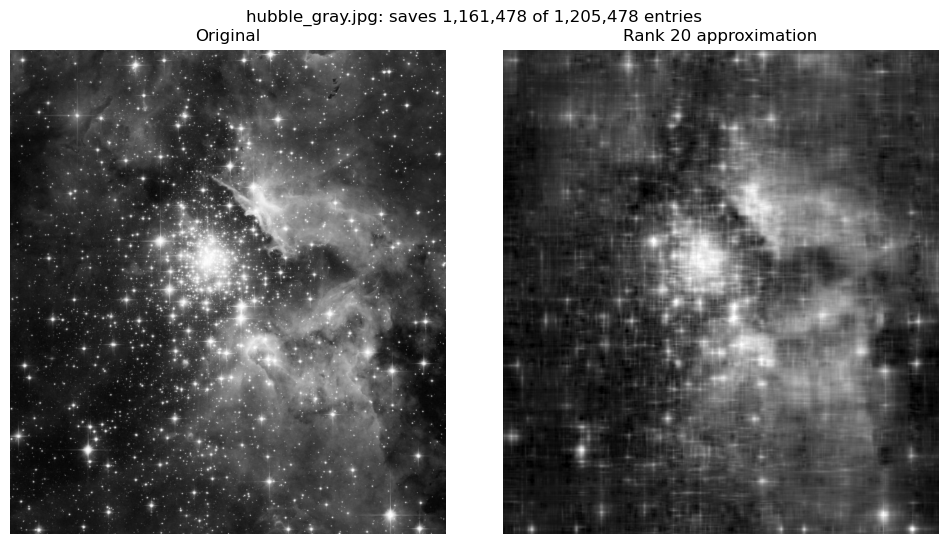

Entries saved: 1161478  (lab expects 1,161,478)


In [9]:
def compress_image(filename, s):
    """Plot the original image found at 'filename' and the rank s approximation
    of the image found at 'filename.' State in the figure title the difference
    in the number of entries used to store the original image and the
    approximation.

    Parameters:
        filename (str): Image file path.
        s (int): Rank of new image.
    """
    image = imread(filename) / 255.
    if image.ndim == 2:
        approx, entries = svd_approx(image, s)
        cmap = "gray"
    else:
        layers = [svd_approx(image[:, :, c], s) for c in range(3)]
        approx = np.dstack([l[0] for l in layers])
        entries = sum(l[1] for l in layers)
        cmap = None
    approx = np.clip(approx, 0, 1)

    fig, ax = plt.subplots(1, 2, figsize=(10, 5.5))
    ax[0].imshow(image, cmap=cmap); ax[0].set_title("Original")
    ax[1].imshow(approx, cmap=cmap); ax[1].set_title(f"Rank {s} approximation")
    for a in ax: a.axis("off")
    plt.suptitle(f"{os.path.basename(filename)}: saves {image.size - entries:,} of {image.size:,} entries")
    plt.tight_layout()
    plt.show()
    return image.size - entries

saved = compress_image(os.path.join(DATA, "hubble_gray.jpg"), 20)
print("Entries saved:", saved, " (lab expects 1,161,478)")

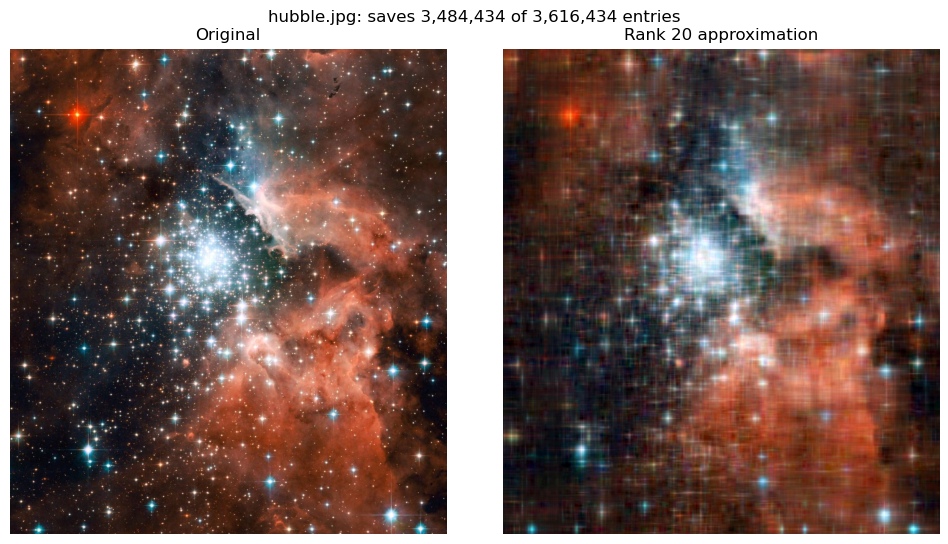

In [10]:
compress_image(os.path.join(DATA, "hubble.jpg"), 20);

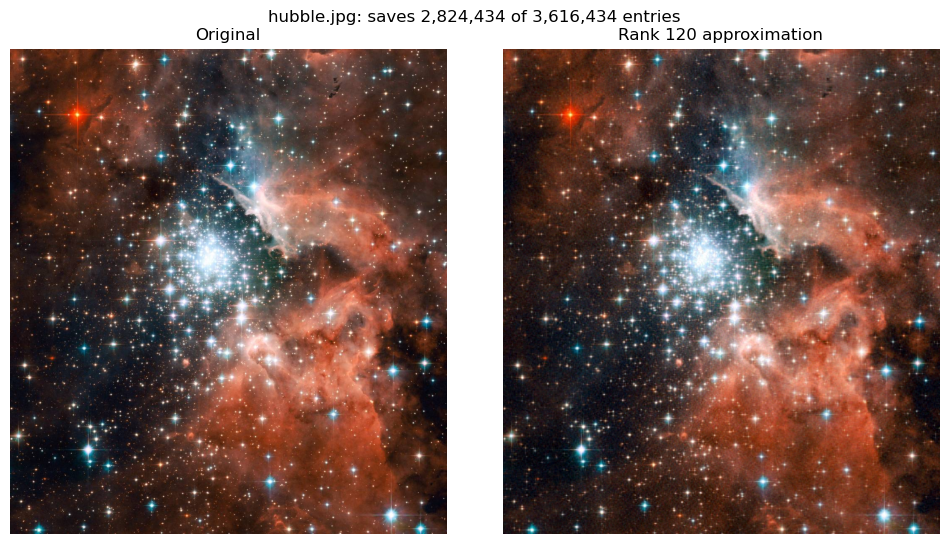

In [11]:
compress_image(os.path.join(DATA, "hubble.jpg"), 120);

### A sweep of ranks (cf. Fig. 3 of the lab)

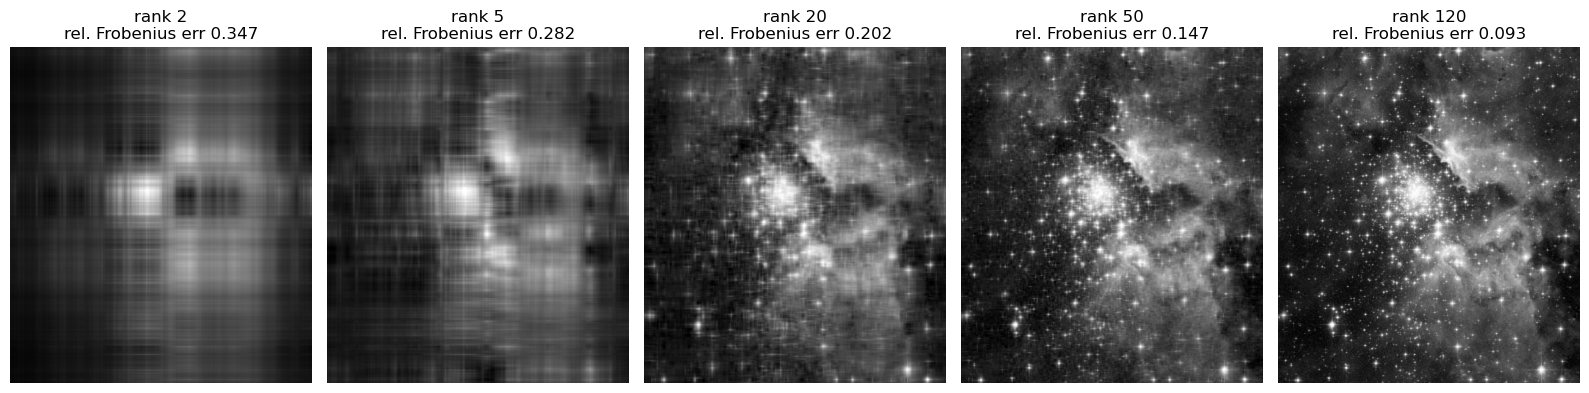

In [12]:
U, sig, Vh = la.svd(hubble_gray, full_matrices=False)
ranks = [2, 5, 20, 50, 120]
fig, ax = plt.subplots(1, len(ranks), figsize=(16, 3.8))
for a, s in zip(ax, ranks):
    a.imshow(np.clip((U[:, :s] * sig[:s]) @ Vh[:s], 0, 1), cmap="gray")
    rel = la.norm(hubble_gray - (U[:, :s] * sig[:s]) @ Vh[:s]) / la.norm(hubble_gray)
    a.set_title(f"rank {s}\nrel. Frobenius err {rel:.3f}")
    a.axis("off")
plt.tight_layout(); plt.show()

## Additional Material: Animating the Reconstruction

The lab's `FuncAnimation` example, rendered to inline HTML. The frame shows the color image as the rank grows from 1 to 100.

In [13]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

layers = [la.svd(hubble[:, :, c], full_matrices=False) for c in range(3)]
def color_rank(s):
    return np.clip(np.dstack([(U[:, :s] * S[:s]) @ V[:s] for U, S, V in layers]), 0, 1)

# A small, low-dpi figure keeps the embedded animation from bloating the notebook.
frames = [1, 3, 8, 20, 50, 100]
fig = plt.figure(figsize=(3, 3.4), dpi=60)
plt.axis("off")
im = plt.imshow(color_rank(frames[0]), animated=True)
title = plt.title("")

def update(k):
    title.set_text(f"Rank {frames[k]} Approximation")
    im.set_array(color_rank(frames[k]))
    return im, title

anim = FuncAnimation(fig, update, frames=len(frames), interval=400, blit=True)
plt.close(fig)
HTML(anim.to_jshtml())

## Discussion

- Algorithm 1 is easy to write, but forming $A^HA$ squares the condition number. Singular values below about $\sqrt{\varepsilon_{\text{mach}}}\,\sigma_1$ lose accuracy, which is why libraries use Golub-Kahan bidiagonalization instead.
- For the $1158\times1041$ Hubble image, rank 20 keeps the overall structure with about 3.6% of the storage. By rank 120 the approximation is hard to tell apart from the original.